<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-018-spin-models-monte-carlo.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 018 <br>
<hr/>

# Lab 018 — Monte Carlo for classical spin models

In Lecture 4 a network trained **with labels** found the critical temperature of the 2D Ising model. In Lecture 5 we drop the labels.
Before any learning, we need data, and we need to know the physics well enough to judge what the learning algorithms tell us.

This notebook is about **classical** spin models. Every spin is a number $s_i=\pm1$; a configuration $\boldsymbol s$ is a definite
"photograph" of the system, and thermal equilibrium is the Boltzmann distribution over such photographs. Monte Carlo samples this distribution
exactly (up to statistical errors). Quantum spin models, with non-commuting operators, superpositions, and snapshots produced by projective
measurements, come later in the course.

We begin with the physics of the frustrated $J_1$–$J_2$ model: its competing couplings and ground states, the frustration at $g=J_2/J_1=1/2$, its order parameters, and what mean-field theory and the literature say about the finite-temperature phase diagram. To sample it we build a Metropolis sampler in JAX with `jit`, `vmap` and `lax.scan`, which runs hundreds of independent chains in parallel, and for the Ising model near $T_c$ the Swendsen–Wang cluster algorithm. With these samplers we produce the two data sets used in Labs 019 and 020: the 2D Ising model for several lattice sizes, for finite-size scaling, and the $J_1$–$J_2$ model on a grid in the $(g,T)$ plane. The last section scans the $(g,T)$ plane as a physicist would and asks which quantity should be plotted and how expensive a dense scan is.

> In Google Colab, run the cells in order; JAX is pre-installed in Colab and the notebook runs on the CPU (central processing unit).
> The two data-set cells take a few minutes each.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"                     # the whole notebook runs on the CPU
import time, json, itertools
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import ellipk

import jax
import jax.numpy as jnp
from jax import lax

print("JAX", jax.__version__, "| devices:", jax.devices())

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])            # s = -1 white, s = +1 navy
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SLIDE_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
               "ytick.labelsize": 10, "legend.fontsize": 10}   # slide figures, drawn at their physical size

FIG = "figures"; os.makedirs(FIG, exist_ok=True)
DATA = "data"; os.makedirs(DATA, exist_ok=True)
NUMBERS = {}                                                 # numbers quoted on the slides
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")

TC_ISING = 2.0 / np.log(1.0 + np.sqrt(2.0))                 # Onsager: exact T_c of the 2D Ising model (J = k_B = 1)
print(f"Onsager T_c = 2 / ln(1 + sqrt 2) = {TC_ISING:.6f}")

JAX 0.11.0 | devices: [CpuDevice(id=0)]
Onsager T_c = 2 / ln(1 + sqrt 2) = 2.269185


<hr/>
## 1. The model

Spins $s_i=\pm1$ sit on an $L\times L$ square lattice with periodic boundaries. Every spin has **four nearest neighbours** (left, right, up, down)
and **four next-nearest neighbours** (along the diagonals). The energy is
$$
H(\boldsymbol s) = -J_1\sum_{\langle i,j\rangle} s_i s_j \;+\; J_2\sum_{\langle\langle i,j\rangle\rangle} s_i s_j ,
\qquad J_1>0,\quad J_2\ge 0,
$$
with $\langle i,j\rangle$ the $2N$ nearest-neighbour bonds and $\langle\langle i,j\rangle\rangle$ the $2N$ diagonal bonds ($N=L^2$).

* $J_1>0$ is **ferromagnetic**: nearest neighbours want to be parallel.
* $J_2>0$ (with the $+$ sign in $H$) is **antiferromagnetic**: diagonal neighbours want to be antiparallel.

We set $J_1=1$ and use the single control parameter
$$
g = J_2/J_1 .
$$
Together with the temperature $T$ (with $k_B=1$) this gives a **two-dimensional phase diagram** in the $(g,T)$ plane.

Two limits are already understood. At $g=0$ the model is the 2D Ising model, solved exactly by Onsager, with $T_c=2/\ln(1+\sqrt2)\approx 2.269$.
For $g\to\infty$ ($J_1\to0$) only diagonal bonds remain. The diagonal bonds connect sites of the same chessboard colour, so the lattice splits into
**two independent square lattices** (rotated by $45^\circ$), each an antiferromagnetic Ising model with coupling $J_2$. Flipping every second spin
of such a lattice maps the antiferromagnet onto a ferromagnet with the same partition function, so each sub-lattice orders at
$T = J_2\,T_c^{\rm Ising}$, i.e. $T_c/J_1 \to g\,T_c^{\rm Ising}$ for large $g$.

Between these limits the two couplings **compete**, and that is where the interesting physics is.

### 1.1 Ground states

At $T=0$ the system sits in the configuration of lowest energy. Consider three candidate patterns and count the bonds per spin (2 nearest-neighbour bonds and 2 diagonal bonds per spin):

| pattern | nearest-neighbour bonds | diagonal bonds | energy per spin $E/N$ |
|---|---|---|---|
| ferromagnet (all up) | all satisfied: $s_is_j=+1$ | all frustrated: $s_is_j=+1$ | $-2J_1+2J_2$ |
| Néel (chessboard) | all broken: $s_is_j=-1$ | $s_is_j=+1$ | $+2J_1+2J_2$ |
| stripes (columns $+,-,+,-$) | horizontal $-1$, vertical $+1$: net $0$ | all satisfied: $s_is_j=-1$ | $-2J_2$ |

The Néel state is never favourable for $J_1>0$. The ferromagnet and the stripe state have equal energy when $-2J_1+2J_2=-2J_2$, i.e. at
$$
g = \tfrac12 .
$$
For $g<1/2$ the ground state is **ferromagnetic** (2 states: all up, all down). For $g>1/2$ it is the **stripe** (also called *collinear* or
*super-antiferromagnetic*) state: 4 states (vertical or horizontal stripes, and the global flip).

At exactly $g=1/2$ a single ferromagnetic row can be inserted into a stripe pattern at no energy cost, and many mixed patterns become
degenerate: the system is **frustrated**, it cannot satisfy both couplings, and the number of ground states grows exponentially with the system size.

The table only compared three guesses. On a small lattice we can check **all** $2^{N}$ configurations, which is a good first exercise in JAX.

### 1.2 Exhaustive enumeration on a $4\times4$ lattice

A $4\times4$ lattice has $2^{16}=65\,536$ configurations, few enough to compute the energy of every one of them; this is also a first look at `vmap` and `jit`. We write the energy of **one** configuration, then let `jax.vmap` turn it into a function of a whole batch, and `jax.jit` compile it.

Two building blocks are used throughout the notebook. The function `jnp.roll(s, 1, axis)` shifts the lattice by one site with periodic wrap-around, so `s * jnp.roll(s, 1, 0)` lists the products over all vertical bonds at once. And the energy splits into two integers, $H = -J_1\,B_1(\boldsymbol s) + J_2\,B_2(\boldsymbol s)$, with $B_1=\sum_{\langle ij\rangle}s_is_j$ and $B_2=\sum_{\langle\langle ij\rangle\rangle}s_is_j$; we compute $B_1$, $B_2$ once and then get $H$ for **every** $g$ for free.

In [2]:
def bond_sums(s):
    # B1 = sum over nearest-neighbour bonds of s_i s_j,  B2 = same over diagonal bonds  (each bond counted once)
    b1 = jnp.sum(s * jnp.roll(s, 1, 0)) + jnp.sum(s * jnp.roll(s, 1, 1))
    b2 = jnp.sum(s * jnp.roll(s, (1, 1), (0, 1))) + jnp.sum(s * jnp.roll(s, (1, -1), (0, 1)))
    return b1, b2

def all_configs(L):
    n = L * L
    idx = jnp.arange(2**n, dtype=jnp.int32)
    bits = (idx[:, None] >> jnp.arange(n)) & 1
    return (2 * bits - 1).reshape(-1, L, L).astype(jnp.float32)

S4 = all_configs(4)
B1, B2 = jax.jit(jax.vmap(bond_sums))(S4)          # one call, 65 536 configurations
print(S4.shape, "configurations;  B1 range", int(B1.min()), int(B1.max()), "; B2 range", int(B2.min()), int(B2.max()))

g_scan = np.linspace(0, 1, 201)
E = -np.asarray(B1)[None, :] + g_scan[:, None] * np.asarray(B2)[None, :]     # E[g, config]
E0 = E.min(1)
degeneracy = (E <= E0[:, None] + 1e-9).sum(1)
for gv in (0.0, 0.25, 0.5, 0.75, 1.0):
    i = np.argmin(abs(g_scan - gv))
    print(f"g = {gv:.2f}:  E0/N = {E0[i]/16:+.4f}   ground-state degeneracy = {degeneracy[i]}")
NUMBERS["degeneracy_4x4_g05"] = int(degeneracy[np.argmin(abs(g_scan - 0.5))])
NUMBERS["degeneracy_4x4_g025"] = int(degeneracy[np.argmin(abs(g_scan - 0.25))])
NUMBERS["degeneracy_4x4_g075"] = int(degeneracy[np.argmin(abs(g_scan - 0.75))])

(65536, 4, 4) configurations;  B1 range -32 32 ; B2 range -32 32
g = 0.00:  E0/N = -2.0000   ground-state degeneracy = 2
g = 0.25:  E0/N = -1.5000   ground-state degeneracy = 2
g = 0.50:  E0/N = -1.0000   ground-state degeneracy = 30
g = 0.75:  E0/N = -1.5000   ground-state degeneracy = 4
g = 1.00:  E0/N = -2.0000   ground-state degeneracy = 4


The exhaustive search confirms the table: $E_0/N = -2+2g$ for $g<1/2$ (2 ferromagnetic states), $E_0/N=-2g$ for $g>1/2$ (4 stripe states),
and a **jump of the degeneracy at $g=1/2$**. On larger lattices that number grows exponentially with $L$; a $4\times4$ lattice only hints at it.

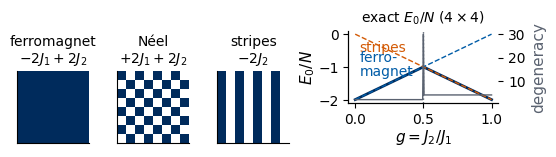

30 degenerate ground states of the 4x4 lattice at g = 1/2


In [3]:
L_draw = 8
x, y = np.meshgrid(np.arange(L_draw), np.arange(L_draw), indexing="ij")
patterns = {"ferromagnet": np.ones((L_draw, L_draw)),
            "Néel": (-1.0) ** (x + y),
            "stripes": (-1.0) ** y}

# one of the degenerate ground states at g = 1/2: stripes with one ferromagnetic column pair inserted
ig = np.argmin(abs(g_scan - 0.5))
gs_half = np.asarray(S4)[E[ig] <= E0[ig] + 1e-9]

W, H = 5.5, 1.42                                        # physical size on the slide (full text width)
with plt.rc_context(SLIDE_STYLE):
    fig = plt.figure(figsize=(W, H))
    box = lambda x0, y0, w, h: fig.add_axes([x0 / W, y0 / H, w / W, h / H])   # axes placed in inches
    for k, (name, p) in enumerate(patterns.items()):
        ax = box(0.14 + 1.0 * k, 0.05, 0.72, 0.72)
        ax.imshow(p, cmap=SPIN_CMAP, vmin=-1, vmax=1)
        e = {"ferromagnet": r"$-2J_1+2J_2$", "Néel": r"$+2J_1+2J_2$", "stripes": r"$-2J_2$"}[name]   # energy per spin E/N
        ax.set_title(f"{name}\n{e}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax = box(3.45, 0.45, 1.5, 0.72)
    ax.plot(g_scan, E0 / 16, color=UJNavy, lw=2)
    ax.plot(g_scan, -2 + 2 * g_scan, "--", color=UJBlue, lw=1)
    ax.plot(g_scan, -2 * g_scan, "--", color=DSOrange, lw=1)
    ax.text(0.03, -0.2, "stripes", color=DSOrange, fontsize=10, va="top")
    ax.text(0.03, -1.35, "ferro-\nmagnet", color=UJBlue, fontsize=10, va="bottom", ha="left", linespacing=1.0)
    ax.axvline(0.5, color=UJGray, ls=":", lw=1)
    ax2 = ax.twinx(); ax2.plot(g_scan, degeneracy, color=UJGray, lw=1); ax2.set_ylabel("degeneracy", color=UJGray)
    ax2.spines["top"].set_visible(False)
    ax.set_title(r"exact $E_0/N$ ($4\times4$)", fontsize=10)
    ax.set_xlabel("$g=J_2/J_1$", labelpad=1); ax.set_ylabel("$E_0/N$", labelpad=1)
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([-2, -1, 0])
    fig.savefig(f"{FIG}/gen_j1j2_ground_states.png", dpi=200); plt.show()
print(f"{len(gs_half)} degenerate ground states of the 4x4 lattice at g = 1/2")

### 1.3 Order parameters

Each ordered phase is characterised by a quantity that is non-zero in that phase and zero elsewhere, an **order parameter**. For ordering
patterns that repeat with a wave vector $\boldsymbol k$ the natural choice is the Fourier component of the spins,
$$
m_{\boldsymbol k}(\boldsymbol s) = \frac1N\sum_{\boldsymbol r} s_{\boldsymbol r}\, e^{i\boldsymbol k\cdot\boldsymbol r},
$$
and its square summed over many $\boldsymbol k$ is the **static structure factor** $S(\boldsymbol k)=N\langle|m_{\boldsymbol k}|^2\rangle$, measured in neutron scattering.

| phase | ordering wave vector | order parameter |
|---|---|---|
| ferromagnet | $\boldsymbol k=(0,0)$ | $m = \frac1N\sum_r s_r$ |
| stripes | $(\pi,0)$ and $(0,\pi)$ | $m_{\rm str} = \sqrt{m_{(\pi,0)}^2 + m_{(0,\pi)}^2}$ |
| Néel | $(\pi,\pi)$ | $m_{(\pi,\pi)}$ |

The stripe order parameter combines the two wave vectors because vertical and horizontal stripes have the same energy.

The table contains the key point for this lecture: the magnetisation $m$ is **zero** in the stripe phase: half of the spins are up and half are down.
A scan of $\langle|m|\rangle$ over the $(g,T)$ plane therefore sees the stripe phase as "disordered". To see it, one has to *know* that stripes
exist and measure $m_{\rm str}$. For the $J_1$–$J_2$ model we know this from the ground-state analysis. For a new material or a new model we
often do not know which quantity to plot.

In [4]:
def order_parameters(s):
    # s: (..., L, L) with values +-1.  Returns |m|, m_stripe, m_neel, and energy terms B1, B2 per spin.
    L = s.shape[-1]
    ph = jnp.where(jnp.arange(L) % 2 == 0, 1.0, -1.0)                 # e^{i pi x} = (-1)^x
    m = s.mean((-2, -1))
    m_pi0 = (s * ph[:, None]).mean((-2, -1))                           # k = (pi, 0)
    m_0pi = (s * ph[None, :]).mean((-2, -1))                           # k = (0, pi)
    m_pipi = (s * ph[:, None] * ph[None, :]).mean((-2, -1))           # k = (pi, pi)
    return {"m": jnp.abs(m), "m_str": jnp.sqrt(m_pi0**2 + m_0pi**2), "m_neel": jnp.abs(m_pipi)}

for name, p in patterns.items():
    o = order_parameters(jnp.asarray(p))
    print(f"{name:12s}  |m| = {float(o['m']):.2f}   m_str = {float(o['m_str']):.2f}   m_Neel = {float(o['m_neel']):.2f}")

ferromagnet   |m| = 1.00   m_str = 0.00   m_Neel = 0.00
Néel          |m| = 0.00   m_str = 0.00   m_Neel = 1.00
stripes       |m| = 0.00   m_str = 1.00   m_Neel = 0.00


### 1.4 Mean-field theory at finite temperature

The simplest approximation at $T>0$ is mean-field theory: replace the neighbours of spin $i$ by their thermal averages $\langle s_j\rangle$. The spin then feels the field
$$
h_i = J_1\sum_{j\in{\rm nn}(i)}\langle s_j\rangle - J_2\sum_{j\in{\rm nnn}(i)}\langle s_j\rangle, \qquad \langle s_i\rangle = \tanh(\beta h_i).
$$
For the ferromagnetic ansatz $\langle s_j\rangle = m$ this gives $h = (4J_1-4J_2)m$, so $m=\tanh(\beta(4J_1-4J_2)m)$, which has a non-zero solution below
$T^{\rm MF}_{\rm FM} = 4J_1-4J_2 = 4(1-g)$. For the stripe ansatz (columns alternate, $\langle s_j\rangle=\pm m$) the nearest-neighbour contributions cancel (two parallel, two antiparallel),
and all four diagonal neighbours are antiparallel, so $h = 4J_2 m$ and $T^{\rm MF}_{\rm str}=4J_2 = 4g$.

Mean-field theory predicts the two lines meet at $g=1/2$ at $T=2$. This is **wrong**: fluctuations between the many degenerate ground states
destroy the order, and the true transition temperature goes to **zero** at $g=1/2$. Mean field also overestimates $T_c$ at $g=0$
($4$ instead of $2.269$), because it neglects fluctuations, which are strong in two dimensions.

Large-scale numerics give the following picture, although the questions are subtle and partly still debated. For $g<1/2$ there is a continuous transition from the paramagnet to the ferromagnet, in the 2D Ising universality class, with $T_c(g)$ decreasing to $0$ at $g=1/2$. For $g>1/2$ there is a transition to the stripe phase. For $g$ slightly above $1/2$ it is **weakly first order**; above a multicritical point it is
continuous, with exponents that vary along the line (Ashkin–Teller criticality) and approach the Ising ones as $g\to\infty$.
Kalz, Honecker, Fuchs and Pruschke (Eur. Phys. J. B **65**, 533 (2008)) found weakly first-order transitions for moderate $J_2>J_1/2$;
Jin, Sen and Sandvik (Phys. Rev. Lett. **108**, 045702 (2012)) and Jin, Sen, Guo and Sandvik (Phys. Rev. B **87**, 144406 (2013)) placed the
multicritical point at $g^*\approx0.67$ and showed that continuous transitions above $g^*$ can look first order on finite lattices;
tensor-network calculations by Li and Yang (Phys. Rev. E **104**, 024118 (2021)) suggest that the first-order window is narrower.

The lesson: even for a model this simple, the phase diagram required decades of work, careful finite-size analysis, and knowledge of the
right order parameters. In Lab 020 we ask how much of it an algorithm can find **without** being told what to look for.

### 1.5 Thermal averages and their estimators

Before we sample, we fix what every number in this notebook means. In thermal equilibrium at temperature $T$ (inverse temperature $\beta=1/T$, $k_B=1$) a configuration $\boldsymbol s$ occurs with the Boltzmann probability
$$
p(\boldsymbol s)=\frac{e^{-\beta H(\boldsymbol s)}}{Z},\qquad Z=\sum_{\boldsymbol s}e^{-\beta H(\boldsymbol s)},
$$
and an observable $O(\boldsymbol s)$ of a single configuration has the thermal average $\langle O\rangle=\frac1Z\sum_{\boldsymbol s}O(\boldsymbol s)\,e^{-\beta H(\boldsymbol s)}$. The partition function also generates the thermodynamics: the energy per spin is the first derivative of $\ln Z$ with respect to $\beta$, and the specific heat per spin is the second derivative, which equals the variance of the energy,
$$
\langle e\rangle=\frac{\langle H\rangle}{N}=-\frac1N\,\frac{\partial\ln Z}{\partial\beta},\qquad
c=\frac{\beta^2}{N}\,\frac{\partial^2\ln Z}{\partial\beta^2}=\frac{\beta^2}{N}\big(\langle H^2\rangle-\langle H\rangle^2\big)=N\beta^2\big(\langle e^2\rangle-\langle e\rangle^2\big).
$$
On the $4\times4$ lattice the sums over all $2^{16}$ configurations can be done, and the function `exact_4x4` below computes $\langle e\rangle$, $\langle|m|\rangle$ and $\langle m_{\rm str}\rangle$ literally as these weighted sums. On larger lattices Monte Carlo draws $n$ configurations $\boldsymbol s^{(1)},\dots,\boldsymbol s^{(n)}$ with probability $p(\boldsymbol s)$ at each $(g,T)$, and every average is estimated by the sample mean $\overline{O}=\frac1n\sum_{k=1}^nO(\boldsymbol s^{(k)})$. The table lists each observable in both forms; the estimators are those of the functions `energy_per_spin`, `order_parameters` and `observables` below. Here $e_k=H(\boldsymbol s^{(k)})/N$ (computed as $-\frac1{2N}\sum_i s_ih_i$, since every bond appears twice in $\sum_is_ih_i$), $m_k=\frac1N\sum_is^{(k)}_i$, and $\overline{x}$ is the mean over the $n$ samples. On a finite lattice without a field $\langle m\rangle=0$ by the symmetry $\boldsymbol s\to-\boldsymbol s$, which is why $|m|$ is used.

| observable | definition through $Z$ | estimator from $n$ samples (as in the code) |
|---|---|---|
| energy per spin | $\langle e\rangle=-\frac1N\partial_\beta\ln Z$ | $\overline{e}=\frac1n\sum_ke_k$ |
| magnetisation | $\langle\lvert m\rvert\rangle=\frac1Z\sum_{\boldsymbol s}\lvert m(\boldsymbol s)\rvert e^{-\beta H}$ | $\overline{\lvert m\rvert}=\frac1n\sum_k\lvert m_k\rvert$ |
| stripe order | $\langle m_{\rm str}\rangle$, $m_{\rm str}=\sqrt{m_{(\pi,0)}^2+m_{(0,\pi)}^2}$, $m_{(\pi,0)}=\frac1N\sum_{\boldsymbol r}(-1)^{x}s_{\boldsymbol r}$, $m_{(0,\pi)}=\frac1N\sum_{\boldsymbol r}(-1)^{y}s_{\boldsymbol r}$ | $\overline{m_{\rm str}}=\frac1n\sum_km_{{\rm str},k}$ |
| Néel order | $\langle\lvert m_{(\pi,\pi)}\rvert\rangle$, $m_{(\pi,\pi)}=\frac1N\sum_{\boldsymbol r}(-1)^{x+y}s_{\boldsymbol r}$ | $\frac1n\sum_k\lvert m_{(\pi,\pi),k}\rvert$ |
| specific heat | $c=\frac{\beta^2}{N}\partial^2_\beta\ln Z=N\beta^2\big(\langle e^2\rangle-\langle e\rangle^2\big)$ | $N\beta^2\big(\overline{e^2}-\overline{e}^{\,2}\big)$ (Section 5 maps); $N\beta^2\,\frac{1}{n-1}\sum_k(e_k-\overline e)^2$ (Section 5.1) |

All variances in the maps of Section 5 are population variances (division by $n$, `jnp.var`); the subsampling study of Section 5.1 uses the unbiased variance (division by $n-1$, `var(ddof=1)`), which matters for its small subsets of 10 samples.

Section 2.2 also uses a dynamical quantity, the autocorrelation of $|m|$ along a chain. With $x_t=|m|$ after step $t$ of one chain, $\delta x_t=x_t-\overline{x}$ (mean over the chain) and $v=\overline{\delta x^2}$, its definition and estimator are
$$
A(t)=\frac{\langle x_sx_{s+t}\rangle-\langle x\rangle^2}{\langle x^2\rangle-\langle x\rangle^2},\qquad
\widehat A(t)=\frac{1}{n_{\rm ch}}\sum_{\rm chains}\frac{1}{v}\,\frac{1}{n-t}\sum_{s=1}^{n-t}\delta x_s\,\delta x_{s+t},
$$
averaged over the $n_{\rm ch}$ chains, and the integrated autocorrelation time is estimated as $\tau=\tfrac12+\sum_{t=1}^{t^*-1}\widehat A(t)$, with $t^*$ the first lag at which $\widehat A(t)<0.05$.

<hr/>
## 2. Metropolis Monte Carlo in JAX

The algorithm, derived in Lab 010, proposes to flip spin $i$ and accepts with probability $\min(1, e^{-\beta\Delta E})$. With the local field
$$
h_i = J_1\sum_{j\in{\rm nn}(i)} s_j - J_2\sum_{j\in{\rm nnn}(i)} s_j ,\qquad \Delta E_i = 2\,s_i\,h_i .
$$

Spins can be flipped *simultaneously* only if they do not interact. For the Ising model the chessboard colouring works,
but here diagonal neighbours have the *same* chessboard colour. We use **four sub-lattices** labelled by $(x \bmod 2,\, y \bmod 2)$:
nearest neighbours differ in one parity, diagonal neighbours in both, so no two spins of one sub-lattice are coupled. In code a sub-lattice
is the strided slice `s[a::2, b::2]`, and we only draw random numbers for the spins we update. One **sweep** = four sub-lattice updates =
one attempted flip per spin.

The JAX structure follows from this. A pure function `sweep(s, key, g, beta)` updates one lattice; randomness is explicit, a pseudo-random number generator (PRNG) `key` goes in and a new key comes out. `lax.scan` repeats a step many times inside one compiled program, with no Python loop overhead. `jax.vmap` maps the whole simulation over **chains**, every chain with its own $g$ and its own random key, so all values of $g$ run at once. `jax.jit` compiles the result into a single program (XLA, Accelerated Linear Algebra, the compiler behind JAX, fuses the array operations; on a graphics processing unit, GPU, the same code runs unchanged).

Each chain is annealed: it starts at the highest temperature and is cooled step by step; at each temperature it first equilibrates for
`n_equil` sweeps and then stores `n_samples` configurations separated by `n_between` sweeps (to reduce correlations between stored samples).
Cooling slowly, rather than starting each temperature from a random state, helps the chain find the ordered state at low $T$.

In [5]:
def local_field(s, g):
    # s: (..., L, L); the rolls act on the two lattice axes, so the same function works for one lattice or a batch
    nn = jnp.roll(s, 1, -2) + jnp.roll(s, -1, -2) + jnp.roll(s, 1, -1) + jnp.roll(s, -1, -1)
    nnn = (jnp.roll(s, (1, 1), (-2, -1)) + jnp.roll(s, (1, -1), (-2, -1))
           + jnp.roll(s, (-1, 1), (-2, -1)) + jnp.roll(s, (-1, -1), (-2, -1)))
    return nn - g * nnn                                     # J1 = 1, J2 = g

def energy_per_spin(s, g):
    return -0.5 * jnp.mean(s * local_field(s, g), axis=(-2, -1))   # each bond appears twice in sum_i s_i h_i

def sweep(s, key, g, beta):
    for a, b in ((0, 0), (0, 1), (1, 0), (1, 1)):          # the four sub-lattices (a Python loop, unrolled by jit)
        key, sub = jax.random.split(key)
        si = s[a::2, b::2]
        dE = 2.0 * si * local_field(s, g)[a::2, b::2]
        accept = jax.random.uniform(sub, si.shape) < jnp.exp(-beta * dE)
        s = s.at[a::2, b::2].set(jnp.where(accept, -si, si))
    return s, key

@partial(jax.jit, static_argnames=("n_equil", "n_samples", "n_between"))
def anneal_chains(s0, keys, gs, Ts, n_equil, n_samples, n_between):
    # s0: (chains, L, L), keys: (chains, 2), gs: (chains,), Ts: (nT,) in the order visited.
    # Returns int8 samples of shape (chains, nT, n_samples, L, L).
    def one_chain(s, key, g):
        def at_T(carry, T):
            step = lambda c, _: (sweep(c[0], c[1], g, 1.0 / T), None)
            carry, _ = lax.scan(step, carry, None, length=n_equil)
            def store(c, _):
                c, _ = lax.scan(step, c, None, length=n_between)
                return c, c[0].astype(jnp.int8)
            return lax.scan(store, carry, None, length=n_samples)
        _, samples = lax.scan(at_T, (s, key), Ts)
        return samples
    return jax.vmap(one_chain)(s0, keys, gs)

def run(L, gs, Ts, n_chains, n_equil, n_samples, n_between, seed):
    # gs: (nG,) couplings; every g gets n_chains independent chains. Returns (nG, nT, n_chains * n_samples, L, L) int8.
    G = jnp.repeat(jnp.asarray(gs, jnp.float32), n_chains)
    k_init, k_run = jax.random.split(jax.random.PRNGKey(seed))
    s0 = jnp.where(jax.random.bernoulli(k_init, 0.5, (G.size, L, L)), 1.0, -1.0)
    out = anneal_chains(s0, jax.random.split(k_run, G.size), G, jnp.asarray(Ts, jnp.float32),
                        n_equil, n_samples, n_between)
    out = np.asarray(out).reshape(len(gs), n_chains, len(Ts), n_samples, L, L)
    return out.transpose(0, 2, 1, 3, 4, 5).reshape(len(gs), len(Ts), n_chains * n_samples, L, L)

### 2.1 Exact benchmarks

Before producing data we test the sampler against two exact results. On the $4\times4$ lattice we know the exact thermal averages for any $g$ from the $2^{16}$ states enumerated above. At $g=0$ and large $L$ the magnetisation must follow Yang's exact result $M(T)=\left(1-\sinh^{-4}(2/T)\right)^{1/8}$ below $T_c$, and the energy must follow Onsager's $u(T)$.

In [6]:
def exact_4x4(g, T):
    e = (-np.asarray(B1) + g * np.asarray(B2)) / 16
    o = order_parameters(S4)
    w = np.exp(-16 * (e - e.min()) / T); w /= w.sum()
    return (w * e).sum(), (w * np.asarray(o["m"])).sum(), (w * np.asarray(o["m_str"])).sum()

checks = [(0.0, 1.5), (0.3, 1.0), (0.5, 0.8), (0.8, 1.5), (1.0, 3.0)]
t0 = time.time()
for g, T in checks:
    smp = run(4, [g], [T], n_chains=256, n_equil=500, n_samples=50, n_between=5, seed=1)[0, 0].astype(np.float32)
    o = order_parameters(jnp.asarray(smp)); e = np.asarray(energy_per_spin(jnp.asarray(smp), g))
    e_ex, m_ex, ms_ex = exact_4x4(g, T)
    print(f"g={g:.1f} T={T:.1f}:  <e> {e.mean():+.4f} (exact {e_ex:+.4f})   <|m|> {float(o['m'].mean()):.4f} "
          f"(exact {m_ex:.4f})   <m_str> {float(o['m_str'].mean()):.4f} (exact {ms_ex:.4f})")
print(f"{time.time() - t0:.1f} s")

g=0.0 T=1.5:  <e> -1.9496 (exact -1.9506)   <|m|> 0.9860 (exact 0.9862)   <m_str> 0.0169 (exact 0.0163)
g=0.3 T=1.0:  <e> -1.3505 (exact -1.3510)   <|m|> 0.9642 (exact 0.9644)   <m_str> 0.0274 (exact 0.0263)


g=0.5 T=0.8:  <e> -0.9380 (exact -0.9396)   <|m|> 0.3291 (exact 0.3257)   <m_str> 0.4001 (exact 0.4023)
g=0.8 T=1.5:  <e> -1.4073 (exact -1.4075)   <|m|> 0.0473 (exact 0.0472)   <m_str> 0.9150 (exact 0.9147)


g=1.0 T=3.0:  <e> -1.1165 (exact -1.1141)   <|m|> 0.1241 (exact 0.1246)   <m_str> 0.6914 (exact 0.6896)
3.9 s


L = 48, 26 temperatures: 13.8 s


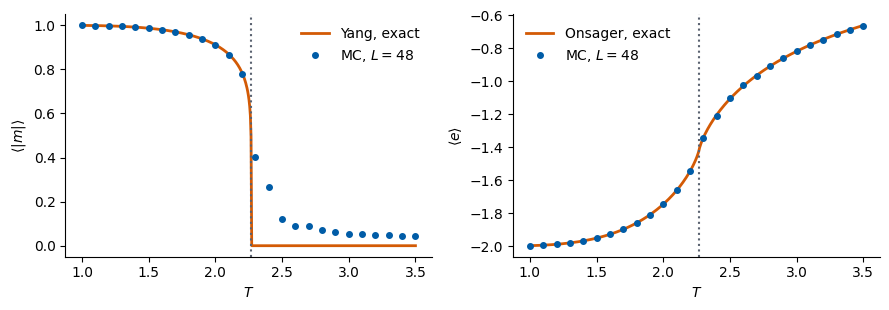

In [7]:
def M_exact(T):
    T = np.asarray(T, float); out = np.zeros_like(T); low = T < TC_ISING
    out[low] = (1 - np.sinh(2 / T[low]) ** -4) ** 0.125
    return out

def u_exact(T):
    K = 1.0 / np.asarray(T, float)
    kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K) ** 2 - 1) * ellipk(kap**2))

T_chk = np.round(np.arange(3.5, 0.99, -0.1), 3)
t0 = time.time()
smp = run(48, [0.0], T_chk, n_chains=16, n_equil=500, n_samples=10, n_between=10, seed=2)[0].astype(np.float32)
print(f"L = 48, {len(T_chk)} temperatures: {time.time() - t0:.1f} s")
sj = jnp.asarray(smp)
m_mc = np.asarray(order_parameters(sj)["m"]).mean(1)
e_mc = np.asarray(energy_per_spin(sj, 0.0)).mean(1)

Tf = np.linspace(1.0, 3.5, 500)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(Tf, M_exact(Tf), color=DSOrange, lw=2, label="Yang, exact"); ax[0].plot(T_chk, m_mc, "o", ms=4, color=UJBlue, label="MC, $L=48$")
ax[1].plot(Tf, u_exact(Tf), color=DSOrange, lw=2, label="Onsager, exact"); ax[1].plot(T_chk, e_mc, "o", ms=4, color=UJBlue, label="MC, $L=48$")
for a, lab in zip(ax, [r"$\langle|m|\rangle$", r"$\langle e\rangle$"]):
    a.axvline(TC_ISING, color=UJGray, ls=":"); a.set_xlabel("$T$"); a.set_ylabel(lab); a.legend(frameon=False)
fig.tight_layout(); savefig(fig, "gen_ising_mc_check.png"); plt.show()

Away from $T_c$ the Monte Carlo points lie on the exact curves. Near $T_c$ the finite lattice rounds the transition: $\langle|m|\rangle$ stays
non-zero above $T_c$ because a finite system always has a finite magnetisation fluctuation. This **finite-size rounding** is the subject of Lab 019.

#### Exercise

Set `n_equil=50` in the cell above and look at the points just below $T_c$. Why does the agreement get worse there first?

### 2.2 Critical slowing down and the Swendsen–Wang algorithm

Near $T_c$ the lattice is made of correlated domains of all sizes up to $L$. Metropolis flips one spin at a time, and a
single flip inside a large domain is almost always rejected (it costs energy at every bond). To turn a whole domain around the chain must
move its boundary step by step, which takes very many sweeps: consecutive samples are nearly copies of each other. This is
**critical slowing down**; the autocorrelation time grows as a power of $L$ (measured below).

The remedy is to flip whole domains at once, but to choose them randomly in a way that keeps the Boltzmann distribution exact. The tool is a
one-line identity for the weight of a single bond, with $p = 1-e^{-2\beta J}$:
$$
e^{\beta J s_is_j} \;=\; e^{\beta J}\Big[\,(1-p) \;+\; p\,\delta_{s_i s_j}\Big].
$$
(For $s_i=s_j$ the bracket is $1$; for $s_i\neq s_j$ it is $1-p=e^{-2\beta J}$.) Read the two terms as a bond variable
$b_{ij}\in\{0,1\}$: "no bond" with weight $1-p$, or "bond" with weight $p$, allowed only between **parallel** spins. Multiplying over all
bonds gives a joint distribution of spins and bonds whose sum over bonds is exactly $e^{-\beta H}$ (Fortuin and Kasteleyn's random-cluster
representation). Sampling the two variables alternately is the algorithm:

1. *bonds given spins:* between every pair of parallel neighbours, place a bond with probability $p$, independently;
2. *spins given bonds:* the only constraint is that bonded spins are equal, so every connected cluster of bonds carries one common sign,
   chosen independently with probability $1/2$ for each cluster.

Each step samples exactly from a conditional distribution of the joint distribution, so the pair of steps leaves $e^{-\beta H}$ invariant.
Near $T_c$ the clusters have all sizes, and one update can turn around a domain as large as the lattice. The method works for ferromagnetic
couplings (a bond requires parallel spins to lower the energy); for the frustrated $J_1$–$J_2$ model we keep Metropolis.

Finding connected clusters is usually a sequential graph search. In array form, as JAX needs it, every site starts with a
label (its own index) and we repeat two operations until nothing changes: each site takes the smallest label among itself and its bonded
neighbours, and then the label of its label (*pointer jumping*). Each iteration is a few `jnp.roll` and `jnp.minimum` operations on the whole
lattice, inside a `lax.while_loop`.

References: R. H. Swendsen, J.-S. Wang, Phys. Rev. Lett. **58**, 86 (1987),
[doi:10.1103/PhysRevLett.58.86](https://doi.org/10.1103/PhysRevLett.58.86); C. M. Fortuin, P. W. Kasteleyn, Physica **57**, 536 (1972);
the single-cluster variant: U. Wolff, Phys. Rev. Lett. **62**, 361 (1989), [doi:10.1103/PhysRevLett.62.361](https://doi.org/10.1103/PhysRevLett.62.361);
textbook: Newman and Barkema (references at the end).

In [8]:
def cluster_labels(bond_r, bond_d):
    # bond_r[x, y]: (x, y) bonded to (x, y+1);  bond_d[x, y]: (x, y) bonded to (x+1, y);  periodic lattice
    L = bond_r.shape[0]
    big = L * L
    bond_l, bond_u = jnp.roll(bond_r, 1, 1), jnp.roll(bond_d, 1, 0)       # bonds to the left / upper neighbour
    def body(carry):
        lab, _ = carry
        m = lab
        m = jnp.minimum(m, jnp.where(bond_r, jnp.roll(lab, -1, 1), big))
        m = jnp.minimum(m, jnp.where(bond_l, jnp.roll(lab, 1, 1), big))
        m = jnp.minimum(m, jnp.where(bond_d, jnp.roll(lab, -1, 0), big))
        m = jnp.minimum(m, jnp.where(bond_u, jnp.roll(lab, 1, 0), big))
        m = m.ravel()[m]                                                  # pointer jumping
        return m, jnp.any(m != lab)
    lab, _ = lax.while_loop(lambda c: c[1], body, (jnp.arange(L * L).reshape(L, L), True))
    return lab

def sw_step(s, key, beta):
    k1, k2, k3 = jax.random.split(key, 3)
    p = 1.0 - jnp.exp(-2.0 * beta)
    bond_r = (s == jnp.roll(s, -1, 1)) & (jax.random.uniform(k1, s.shape) < p)
    bond_d = (s == jnp.roll(s, -1, 0)) & (jax.random.uniform(k2, s.shape) < p)
    lab = cluster_labels(bond_r, bond_d)
    flip = jax.random.bernoulli(k3, 0.5, (s.size,))                       # one coin per cluster label
    return jnp.where(flip[lab], -s, s)

@partial(jax.jit, static_argnames=("n_equil", "n_samples", "n_between"))
def sw_chains(s0, keys, Ts, n_equil, n_samples, n_between):
    def one_chain(s, key):
        def at_T(carry, T):
            def step(c, _):
                s, key = c
                key, k = jax.random.split(key)
                return (sw_step(s, k, 1.0 / T), key), None
            carry, _ = lax.scan(step, carry, None, length=n_equil)
            def store(c, _):
                c, _ = lax.scan(step, c, None, length=n_between)
                return c, c[0].astype(jnp.int8)
            return lax.scan(store, carry, None, length=n_samples)
        return lax.scan(at_T, (s, key), Ts)[1]
    return jax.vmap(one_chain)(s0, keys)

def run_sw(L, Ts, n_chains, n_equil, n_samples, n_between, seed):
    k_init, k_run = jax.random.split(jax.random.PRNGKey(seed))
    s0 = jnp.where(jax.random.bernoulli(k_init, 0.5, (n_chains, L, L)), 1.0, -1.0)
    out = np.asarray(sw_chains(s0, jax.random.split(k_run, n_chains), jnp.asarray(Ts, jnp.float32), n_equil, n_samples, n_between))
    return out.transpose(1, 0, 2, 3, 4).reshape(len(Ts), n_chains * n_samples, L, L)     # (nT, samples, L, L)

# check against exact enumeration of the 4x4 lattice at g = 0; error bars from the spread between independent chains
for T in (1.5, 2.27, 3.0):
    n_ch = 32768
    smp = run_sw(4, [T], n_chains=n_ch, n_equil=50, n_samples=8, n_between=10, seed=41)[0].reshape(n_ch, 8, 4, 4).astype(np.float32)
    e_c = np.asarray(energy_per_spin(jnp.asarray(smp), 0.0)).mean(1); m_c = np.abs(smp.mean((-1, -2))).mean(1)
    e_ex, m_ex, _ = exact_4x4(0.0, T)
    err_e, err_m = e_c.std() / np.sqrt(n_ch), m_c.std() / np.sqrt(n_ch)
    print(f"T = {T}:  <e> {e_c.mean():+.4f} +- {err_e:.4f} (exact {e_ex:+.4f}, {(e_c.mean() - e_ex) / err_e:+.1f} sigma)   "
          f"<|m|> {m_c.mean():.4f} +- {err_m:.4f} (exact {m_ex:.4f}, {(m_c.mean() - m_ex) / err_m:+.1f} sigma)")

T = 1.5:  <e> -1.9510 +- 0.0003 (exact -1.9506, -1.0 sigma)   <|m|> 0.9862 +- 0.0001 (exact 0.9862, +0.7 sigma)


T = 2.27:  <e> -1.5662 +- 0.0010 (exact -1.5650, -1.2 sigma)   <|m|> 0.8441 +- 0.0004 (exact 0.8436, +1.0 sigma)


T = 3.0:  <e> -1.0166 +- 0.0011 (exact -1.0171, +0.4 sigma)   <|m|> 0.6010 +- 0.0006 (exact 0.6013, -0.5 sigma)


To see what the clusters look like, we take one configuration of $L=50$ at $T_c$, draw its Swendsen–Wang clusters (each cluster in its own colour), and show the configuration after one update.

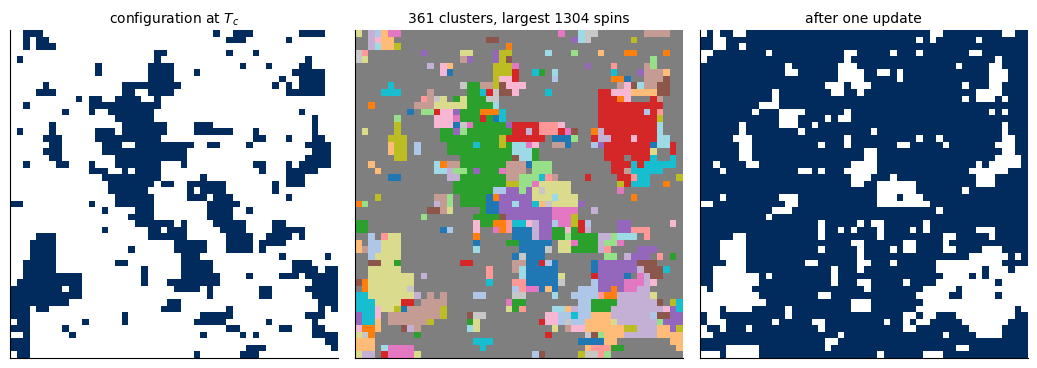

In [9]:
L_pic = 50
s_pic = jnp.asarray(run_sw(L_pic, [TC_ISING], n_chains=1, n_equil=100, n_samples=1, n_between=1, seed=31)[0, 0], jnp.float32)
k1, k2, k3 = jax.random.split(jax.random.PRNGKey(32), 3)
p_pic = 1.0 - np.exp(-2.0 / TC_ISING)
b_r = (s_pic == jnp.roll(s_pic, -1, 1)) & (jax.random.uniform(k1, s_pic.shape) < p_pic)
b_d = (s_pic == jnp.roll(s_pic, -1, 0)) & (jax.random.uniform(k2, s_pic.shape) < p_pic)
lab = np.asarray(jax.jit(cluster_labels)(b_r, b_d))
flip = np.asarray(jax.random.bernoulli(k3, 0.5, (L_pic * L_pic,)))
s_new = np.where(flip[lab], -np.asarray(s_pic), np.asarray(s_pic))
ids, sizes = np.unique(lab, return_counts=True)
colour = np.random.default_rng(0).permutation(len(ids))[np.searchsorted(ids, lab)]
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.6))
ax[0].imshow(np.asarray(s_pic), cmap=SPIN_CMAP, vmin=-1, vmax=1); ax[0].set_title("configuration at $T_c$", fontsize=10)
ax[1].imshow(colour, cmap="tab20", interpolation="nearest"); ax[1].set_title(f"{len(ids)} clusters, largest {sizes.max()} spins", fontsize=10)
ax[2].imshow(s_new, cmap=SPIN_CMAP, vmin=-1, vmax=1); ax[2].set_title("after one update", fontsize=10)
for a in ax: a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); savefig(fig, "gen_ising_sw_clusters.png"); plt.show()
NUMBERS.update(sw_pic_n_clusters=int(len(ids)), sw_pic_largest=int(sizes.max()))

To measure the gain, we compare the autocorrelation of $|m|$ along one chain at $T_c$ for $L=50$, for Metropolis with one sweep per step and for
Swendsen–Wang with one cluster update per step,
$$
A(t) = \frac{\langle |m|_{s}\,|m|_{s+t}\rangle - \langle|m|\rangle^2}{\langle |m|^2\rangle - \langle|m|\rangle^2}.
$$
The faster $A(t)$ decays, the more independent the stored samples are.

L = 50, T = T_c:  integrated autocorrelation time  Metropolis 26.4 sweeps,  Swendsen-Wang 3.4 updates
wall time for 400 steps of 16 chains:  Metropolis 2.7 s,  Swendsen-Wang 29.5 s


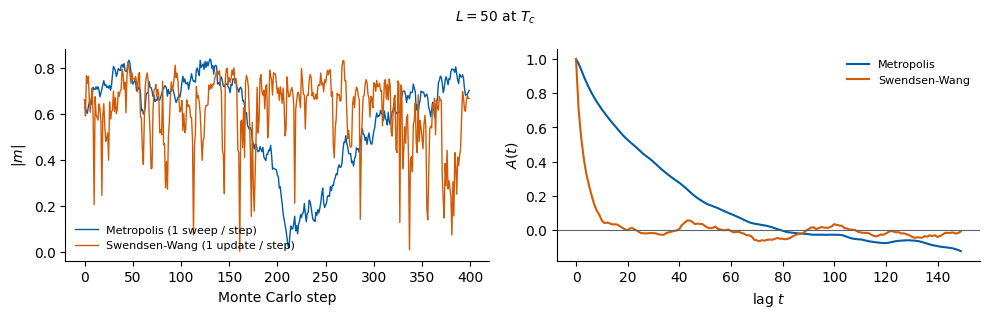

In [10]:
def autocorr(x, t_max):
    x = x - x.mean(-1, keepdims=True)
    v = (x * x).mean(-1)
    return np.array([np.mean((x[:, : x.shape[1] - t] * x[:, t:]).mean(-1) / v) for t in range(t_max)])

L_ac, T_ac, n_steps, n_ch = 50, TC_ISING, 400, 16
t0 = time.time()
met = run(L_ac, [0.0], [T_ac], n_chains=n_ch, n_equil=1000, n_samples=n_steps, n_between=1, seed=21)[0, 0]
t_met = time.time() - t0; t0 = time.time()
sw = run_sw(L_ac, [T_ac], n_chains=n_ch, n_equil=100, n_samples=n_steps, n_between=1, seed=22)[0]
t_sw = time.time() - t0
m_met = np.abs(met.reshape(n_ch, n_steps, -1).mean(-1)); m_sw = np.abs(sw.reshape(n_ch, n_steps, -1).mean(-1))
A_met, A_sw = autocorr(m_met, 150), autocorr(m_sw, 150)
tau = lambda A: 0.5 + A[1:np.argmax(A < 0.05) if (A < 0.05).any() else len(A)].sum()   # integrated autocorrelation time
print(f"L = {L_ac}, T = T_c:  integrated autocorrelation time  Metropolis {tau(A_met):.1f} sweeps,  Swendsen-Wang {tau(A_sw):.1f} updates")
print(f"wall time for {n_steps} steps of {n_ch} chains:  Metropolis {t_met:.1f} s,  Swendsen-Wang {t_sw:.1f} s")
NUMBERS.update(tau_metropolis=round(float(tau(A_met)), 1), tau_sw=round(float(tau(A_sw)), 1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(m_met[0], color=UJBlue, lw=1, label="Metropolis (1 sweep / step)"); ax[0].plot(m_sw[0], color=DSOrange, lw=1, label="Swendsen-Wang (1 update / step)")
ax[0].set_xlabel("Monte Carlo step"); ax[0].set_ylabel(r"$|m|$"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(A_met, color=UJBlue, label="Metropolis"); ax[1].plot(A_sw, color=DSOrange, label="Swendsen-Wang")
ax[1].axhline(0, color=UJGray, lw=0.8); ax[1].set_xlabel("lag $t$"); ax[1].set_ylabel("$A(t)$"); ax[1].legend(frameon=False, fontsize=8)
fig.suptitle(f"$L={L_ac}$ at $T_c$", fontsize=10); fig.tight_layout(); savefig(fig, "gen_ising_autocorr.png"); plt.show()

<hr/>
## 3. Ising data set for several lattice sizes

For finite-size scaling (Lab 019) we need the same temperature grid for several $L$, and nearly **independent** samples close to $T_c$.
We use the Swendsen–Wang sampler: 32 chains per size, each cooled through the temperature grid, 8 samples per temperature separated by
4 cluster updates. We store configurations as bits (`np.packbits`), eight spins per byte.

In [11]:
def pack(configs):
    return np.packbits(configs > 0, axis=-1)

def unpack(packed, L):
    return np.unpackbits(packed, axis=-1, count=L).astype(np.int8) * 2 - 1

ISING_L = [20, 30, 50]
# cooling order; dense steps of 0.02 around T_c, coarse steps of 0.1 elsewhere
ISING_T = np.round(np.concatenate([np.arange(3.5, 2.55, -0.1), np.arange(2.5, 2.095, -0.02), np.arange(2.0, 1.45, -0.1)]), 4)
t_total = time.time()
for L in ISING_L:
    t0 = time.time()
    c = run_sw(L, ISING_T, n_chains=32, n_equil=40, n_samples=8, n_between=4, seed=100 + L)
    np.savez_compressed(f"{DATA}/ising_L{L}.npz", configs=pack(c), T=ISING_T, L=L)
    print(f"L = {L:3d}: {c.shape[0]} temperatures x {c.shape[1]} samples   {time.time() - t0:6.1f} s")
print(f"total {time.time() - t_total:.0f} s")
NUMBERS["ising_L"] = ISING_L; NUMBERS["ising_nT"] = len(ISING_T); NUMBERS["ising_samples_per_T"] = 32 * 8

L =  20: 37 temperatures x 256 samples     37.4 s


L =  30: 37 temperatures x 256 samples     54.2 s


L =  50: 37 temperatures x 256 samples    177.4 s
total 269 s


<hr/>
## 4. $J_1$–$J_2$ data set in the $(g,T)$ plane

One call simulates **all** values of $g$ at once (`vmap` over chains), each chain cooled from $T=4$ to $T=0.1$.

In [12]:
J_L = 32
J_G = np.round(np.arange(0.0, 1.0001, 0.0125), 4)                # 81 couplings
J_T = np.round(np.arange(4.0, 0.0999, -0.05), 4)                 # 79 temperatures, cooling order
t0 = time.time()
cj = run(J_L, J_G, J_T, n_chains=10, n_equil=400, n_samples=10, n_between=10, seed=7)
dt_j1j2 = time.time() - t0
np.savez_compressed(f"{DATA}/j1j2_L{J_L}.npz", configs=pack(cj), g=J_G, T=J_T, L=J_L)
print(cj.shape, f"  {dt_j1j2:.1f} s")
NUMBERS.update(j1j2_L=J_L, j1j2_nG=len(J_G), j1j2_nT=len(J_T), j1j2_samples=cj.shape[2], j1j2_seconds=round(dt_j1j2, 1))

(81, 79, 100, 32, 32)   1186.1 s


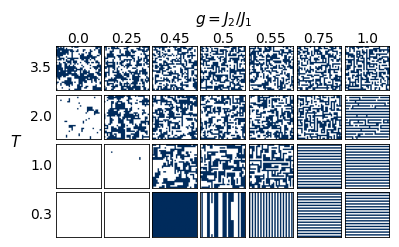

In [13]:
g_show = [0.0, 0.25, 0.45, 0.5, 0.55, 0.75, 1.0]
T_show = [3.5, 2.0, 1.0, 0.3]
with plt.rc_context(SLIDE_STYLE):
    # physical size on the slide (0.7 text width): one row per temperature, one column per coupling
    fig, axes = plt.subplots(len(T_show), len(g_show), figsize=(3.85, 2.3),
                             gridspec_kw=dict(left=0.13, right=0.995, bottom=0.005, top=0.84, wspace=0.08, hspace=0.08))
    for r, T in enumerate(T_show):
        for k, g in enumerate(g_show):
            a = axes[r, k]
            a.imshow(cj[np.argmin(abs(J_G - g)), np.argmin(abs(J_T - T)), -1], cmap=SPIN_CMAP, vmin=-1, vmax=1)
            a.set_xticks([]); a.set_yticks([]); a.spines[:].set_visible(True); a.spines[:].set_linewidth(0.6)
            if r == 0: a.set_title(f"{g}", fontsize=10, pad=2)
            if k == 0: a.set_ylabel(f"{T}", fontsize=10, rotation=0, ha="right", va="center", labelpad=3)
    fig.text(0.565, 0.995, "$g=J_2/J_1$", ha="center", va="top", fontsize=11)
    fig.text(0.01, 0.42, "$T$", ha="left", va="center", fontsize=11)
    fig.savefig(f"{FIG}/gen_j1j2_snapshots.png", dpi=200); plt.show()

At high $T$ every column is noise. At low $T$ and small $g$ the lattice is uniformly up or down; at large $g$ we see
stripes. Near $g=1/2$ even the lowest temperature shows a mixture of ferromagnetic and stripe patches: the frustrated region.

<hr/>
## 5. Choice of observable

Suppose we know nothing about stripes and we do what is natural for a magnet: we measure $\langle|m|\rangle$ at every point of the grid.
Then we measure $\langle m_{\rm str}\rangle$, which requires knowing the stripe pattern. Finally we measure the **specific heat**
$$
c = \frac{N}{T^2}\left(\langle e^2\rangle-\langle e\rangle^2\right),
$$
which does not need any order parameter: it peaks at a transition whatever the order is.

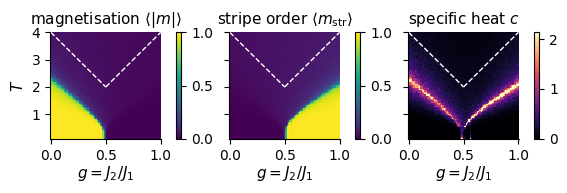

In [14]:
@jax.jit
def observables(s, g):
    # s: (nT, n, L, L) float, g scalar -> per-temperature averages
    o = order_parameters(s)
    e = energy_per_spin(s, g)
    return o["m"].mean(1), o["m_str"].mean(1), e.mean(1), e.var(1)

N = J_L**2
# one coupling at a time keeps the memory small (the whole dataset as float32 would need ~0.7 GB)
res = [observables(jnp.asarray(cj[i], jnp.float32), J_G[i]) for i in range(len(J_G))]
M_map, Ms_map, E_map, varE = (np.stack([np.asarray(r[k]) for r in res]) for k in range(4))
C_map = N * varE / J_T[None, :] ** 2

def show_map(ax, Z, title, cmap="viridis", vmax=None):
    im = ax.pcolormesh(J_G, J_T, Z.T, shading="nearest", cmap=cmap, vmin=0, vmax=vmax, rasterized=True)
    ax.set_xlabel("$g=J_2/J_1$", labelpad=1); ax.set_title(title, fontsize=11)
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([1, 2, 3, 4])
    cb = plt.colorbar(im, ax=ax, fraction=0.08, pad=0.04)
    cb.set_ticks([0, 0.5, 1] if vmax == 1 else [0, 1, 2])

with plt.rc_context(SLIDE_STYLE):
    # physical size on the slide (full text width)
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 1.75), sharey=True, layout="constrained")
    show_map(ax[0], M_map, r"magnetisation $\langle|m|\rangle$", vmax=1)
    show_map(ax[1], Ms_map, r"stripe order $\langle m_{\rm str}\rangle$", vmax=1)
    show_map(ax[2], C_map, r"specific heat $c$", cmap="magma", vmax=np.percentile(C_map, 99))
    ax[0].set_ylabel("$T$")
    gg = np.linspace(0, 1, 101)
    for a in ax:
        a.plot(gg[gg <= 0.5], 4 * (1 - gg[gg <= 0.5]), "--", color="w", lw=1)
        a.plot(gg[gg >= 0.5], 4 * gg[gg >= 0.5], "--", color="w", lw=1)
        a.set_ylim(J_T.min(), J_T.max())
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0.03)
    fig.savefig(f"{FIG}/gen_j1j2_physicist_maps.png", dpi=200); plt.show()

The dashed white lines are the mean-field predictions $T^{\rm MF}=4(1-g)$ and $4g$; they overshoot everywhere and miss the dip to $T_c=0$ at $g=1/2$.

The magnetisation map shows one ordered region, $g<1/2$; the whole stripe phase looks like a paramagnet. The stripe map shows the other ordered region, but only because we told it what pattern to look for. The specific-heat map shows both boundaries without any order parameter. Its price is noise: $c$ is a *variance*, and variances need many more samples than means.

### 5.1 Cost of a dense scan

A boundary from the specific heat needs a peak position, so it needs $c$ on a fine grid with small error bars. How many samples per grid point
does that take? We estimate $c$ from subsets of $n$ samples and look at the scatter of the estimates.

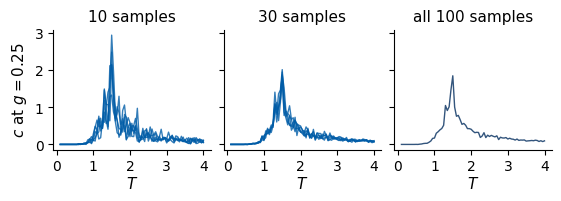

6399 grid points x 100 samples = 639900 configurations


In [15]:
ig = np.argmin(abs(J_G - 0.25))
e_line = np.asarray(energy_per_spin(jnp.asarray(cj[ig], jnp.float32), J_G[ig]))           # (nT, samples)
rng = np.random.default_rng(0)
with plt.rc_context(SLIDE_STYLE):
    # physical size on the slide (full text width)
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 1.9), sharey=True, layout="constrained")
    for a, n in zip(ax, [10, 30, cj.shape[2]]):
        for rep in range(5 if n < cj.shape[2] else 1):
            idx = rng.choice(cj.shape[2], n, replace=False)
            a.plot(J_T, N * e_line[:, idx].var(1, ddof=1) / J_T**2, "-", lw=1, alpha=0.8, color=UJBlue if n < cj.shape[2] else UJNavy)
        a.set_title(f"{n} samples" if n < cj.shape[2] else f"all {n} samples", fontsize=11)
        a.set_xlabel("$T$", labelpad=1); a.set_xticks([0, 1, 2, 3, 4])
    ax[0].set_ylabel("$c$ at $g=0.25$")
    fig.savefig(f"{FIG}/gen_j1j2_cost.png", dpi=200); plt.show()

n_points = len(J_G) * len(J_T)
NUMBERS.update(j1j2_grid_points=n_points, j1j2_total_configs=int(n_points * cj.shape[2]))
print(f"{n_points} grid points x {cj.shape[2]} samples = {n_points * cj.shape[2]} configurations")

With 10 samples per point the peak position of $c$ jumps around from one repetition to the next. A reliable peak needs of order a hundred
decorrelated samples per point, and the decorrelation time itself grows near the transition (critical slowing down). In a laboratory, every
grid point is a separate preparation of the sample at a given pressure, field or temperature.

This is the motivation for Labs 019 and 020, which ask two questions. Can an algorithm that has never been told about magnetisation or stripes find the ordered phases from raw snapshots? And can it do this from a **coarse** scan, and tell us where a dense scan is worth paying for?

<hr/>
## References

* L. Onsager, *Crystal statistics. I. A two-dimensional model with an order-disorder transition*, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117)
* C. N. Yang, *The spontaneous magnetization of a two-dimensional Ising model*, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808)
* A. Kalz, A. Honecker, S. Fuchs, T. Pruschke, *Phase diagram of the Ising square lattice with competing interactions*, Eur. Phys. J. B **65**, 533 (2008), [arXiv:0805.0983](https://arxiv.org/abs/0805.0983)
* S. Jin, A. Sen, A. W. Sandvik, *Ashkin-Teller criticality and pseudo-first-order behavior in a frustrated Ising model on the square lattice*, Phys. Rev. Lett. **108**, 045702 (2012), [arXiv:1110.5874](https://arxiv.org/abs/1110.5874)
* S. Jin, A. Sen, W. Guo, A. W. Sandvik, *Phase transitions in the frustrated Ising model on the square lattice*, Phys. Rev. B **87**, 144406 (2013), [arXiv:1212.5339](https://arxiv.org/abs/1212.5339)
* H. Li, L.-P. Yang, *Tensor network simulation for the frustrated $J_1$-$J_2$ Ising model on the square lattice*, Phys. Rev. E **104**, 024118 (2021), [arXiv:2103.09464](https://arxiv.org/abs/2103.09464)
* R. H. Swendsen, J.-S. Wang, *Nonuniversal critical dynamics in Monte Carlo simulations*, Phys. Rev. Lett. **58**, 86 (1987), [doi:10.1103/PhysRevLett.58.86](https://doi.org/10.1103/PhysRevLett.58.86)
* C. M. Fortuin, P. W. Kasteleyn, *On the random-cluster model. I. Introduction and relation to other models*, Physica **57**, 536 (1972)
* U. Wolff, *Collective Monte Carlo updating for spin systems*, Phys. Rev. Lett. **62**, 361 (1989), [doi:10.1103/PhysRevLett.62.361](https://doi.org/10.1103/PhysRevLett.62.361)
* M. F. Faulkner, S. Livingstone, *Sampling algorithms in statistical physics: a guide for statistics and machine learning*, Statist. Sci. **39**, 137 (2024), [arXiv:2208.04751](https://arxiv.org/abs/2208.04751)
* Textbook: M. E. J. Newman, G. T. Barkema, *Monte Carlo Methods in Statistical Physics*, Oxford University Press (1999): Metropolis algorithm, equilibration, critical slowing down, cluster algorithms.

<hr/>
## Summary

The $J_1$–$J_2$ Ising model has a ferromagnetic phase ($g<1/2$) and a stripe phase ($g>1/2$); at $g=1/2$ the competition makes the ground
state massively degenerate and the transition temperature vanishes, a point that mean-field theory gets qualitatively wrong. The natural "magnet" observable, $\langle|m|\rangle$, is blind to the stripe phase, so choosing the right observable requires prior knowledge, and fluctuation observables such as $c$, which see every transition, are expensive because they need many samples per grid point.

On the computational side, the whole simulation is one pure `sweep` function, `lax.scan` for time loops, `vmap` over chains and couplings, and `jit` for the whole program. Near $T_c$ local updates slow down; the Swendsen–Wang cluster algorithm (ferromagnetic couplings only) gives nearly independent samples, and its cluster search is a `lax.while_loop` of array operations.

#### Exercises

1. Add a $J_3$ coupling (third neighbours, two sites apart along the axes) to `local_field`. Which sub-lattice decomposition is now needed?
2. Replace annealing by independent random starts at every temperature. What happens to the stripe phase at low $T$ near $g=0.55$?
3. Compute the full structure factor $S(\boldsymbol k)$ with `jnp.fft.fft2` for snapshots at $g=0.25$ and $g=0.75$, $T=0.5$. Where are the peaks?